In [110]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage.metrics import peak_signal_noise_ratio as psnr

# Load original document
original = cv2.imread("Test.jpeg", cv2.IMREAD_GRAYSCALE)

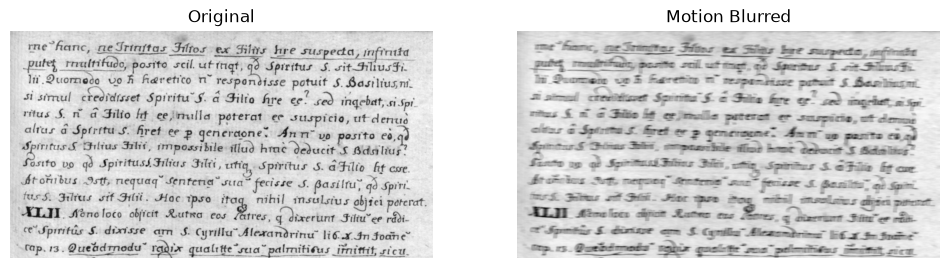

In [111]:
# Create a horizontal motion blur kernel
motion_size = 15

motion_kernel = np.zeros(
    (motion_size, motion_size),
    dtype=np.float32
)

# Fill the centre row with ones
motion_kernel[motion_size // 2, :] = 1

# Normalise so all weights add up to 1
motion_kernel /= motion_kernel.sum()

# Apply motion blur
motion_blurred = cv2.filter2D(
    original, -1, motion_kernel
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(motion_blurred, cmap="gray")
plt.title("Motion Blurred")
plt.axis("off")

plt.show()

In [112]:
# Wiener deconvolution
def wiener_deblur(image, kernel, K=0.001):
    image = image.astype(np.float32) / 255.0

    # Pad and align kernel with the image
    h, w = image.shape
    kh, kw = kernel.shape

    psf = np.zeros((h, w), dtype=np.float32)
    psf[:kh, :kw] = kernel
    psf = np.roll(psf, (-kh // 2 + 1, -kw // 2 + 1), axis=(0, 1))

    # Fourier transforms
    G = np.fft.fft2(image)
    H = np.fft.fft2(psf)

    # Wiener filter
    F = (np.conj(H) / (np.abs(H)**2 + K)) * G

    # Convert back to spatial domain
    restored = np.real(np.fft.ifft2(F))

    return np.clip(restored * 255, 0, 255).astype(np.uint8)



motion_restored = wiener_deblur(
    motion_blurred,
    motion_kernel,
    K=0.001887
)

print("Motion Blurred PSNR:",
      psnr(original, motion_blurred, data_range=255))

print("Motion Restored PSNR:",
      psnr(original, motion_restored, data_range=255))

Motion Blurred PSNR: 24.375881041266506
Motion Restored PSNR: 31.56203209731145


In [113]:
def create_motion_kernel(length=15, angle=0):
    # Create a square matrix filled with zeros.
    # For length=15, this creates a 15x15 kernel.
    kernel = np.zeros((length, length), dtype=np.float32)

    # Set every value in the middle row to 1.
    # This creates a horizontal line representing camera movement.
    # // performs integer division, so 15 // 2 = 7.
    # : means select every column in that row.
    kernel[length // 2, :] = 1

    # Find the centre of the kernel.
    # We rotate around this point so the line stays centred.
    centre = (length / 2 - 0.5, length / 2 - 0.5)

    # Create a rotation matrix using the specified angle.
    # For example, angle=45 rotates the line by 45 degrees.
    # The final argument (1) means no scaling.
    matrix = cv2.getRotationMatrix2D(centre, angle, 1)

    # Rotate the horizontal line using the rotation matrix.
    # warpAffine applies the transformation to the kernel.
    # (length, length) specifies the output dimensions.
    rotated = cv2.warpAffine(
        kernel,
        matrix,
        (length, length)
    )

    # Normalise the kernel so all its values add up to 1.
    # This helps preserve the overall brightness of the image.
    rotated /= rotated.sum()

    # Return the completed motion blur kernel.
    return rotated

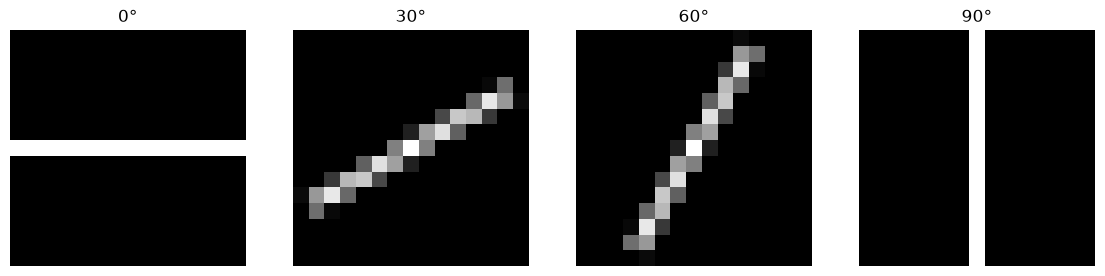

In [114]:
# Define the motion angles we want to test.
angles = [0, 30, 60, 90]

# Create a figure containing four plots in one row.
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

# Loop through each plot and its corresponding angle.
# zip() pairs each axis with an angle.
for ax, angle in zip(axes, angles):

    # Generate a 15x15 motion blur kernel at this angle.
    kernel = create_motion_kernel(15, angle)

    # Display the kernel as a grayscale image.
    # Brighter pixels represent higher kernel weights.
    ax.imshow(kernel, cmap="gray")

    # Display the angle above the kernel.
    ax.set_title(f"{angle}°")

    # Hide the axis numbers and borders.
    ax.axis("off")

# Display all four kernels.
plt.show()

In [115]:
# Define the angles we want to experiment with.
angles = [0, 30, 60, 90]

# Loop through each motion blur angle.
for angle in angles:

    # Generate a motion blur kernel for the current angle.
    kernel = create_motion_kernel(15, angle)

    # Apply the motion blur kernel to the original image.
    # -1 means keep the original image's data type.
    blurred = cv2.filter2D(original, -1, kernel)

    # Attempt to reverse the blur using Wiener deconvolution.
    # We supply the same kernel that caused the blur.
    # K controls the amount of regularisation.
    restored = wiener_deblur(
        blurred,
        kernel,
        K=0.001887
    )

    # Calculate PSNR between the original and blurred image.
    # This measures how much the blur changed the original.
    blurred_score = psnr(
        original,
        blurred,
        data_range=255
    )

    # Calculate PSNR between the original and restored image.
    # Higher PSNR indicates greater pixel-level similarity.
    restored_score = psnr(
        original,
        restored,
        data_range=255
    )

    # Print the PSNR results for the current angle.
    print(
        f"{angle}° | "
        f"Blurred: {blurred_score:.2f} dB | "
        f"Restored: {restored_score:.2f} dB"
    )

0° | Blurred: 24.38 dB | Restored: 31.56 dB
30° | Blurred: 24.80 dB | Restored: 31.13 dB
60° | Blurred: 25.55 dB | Restored: 31.37 dB
90° | Blurred: 25.75 dB | Restored: 31.73 dB


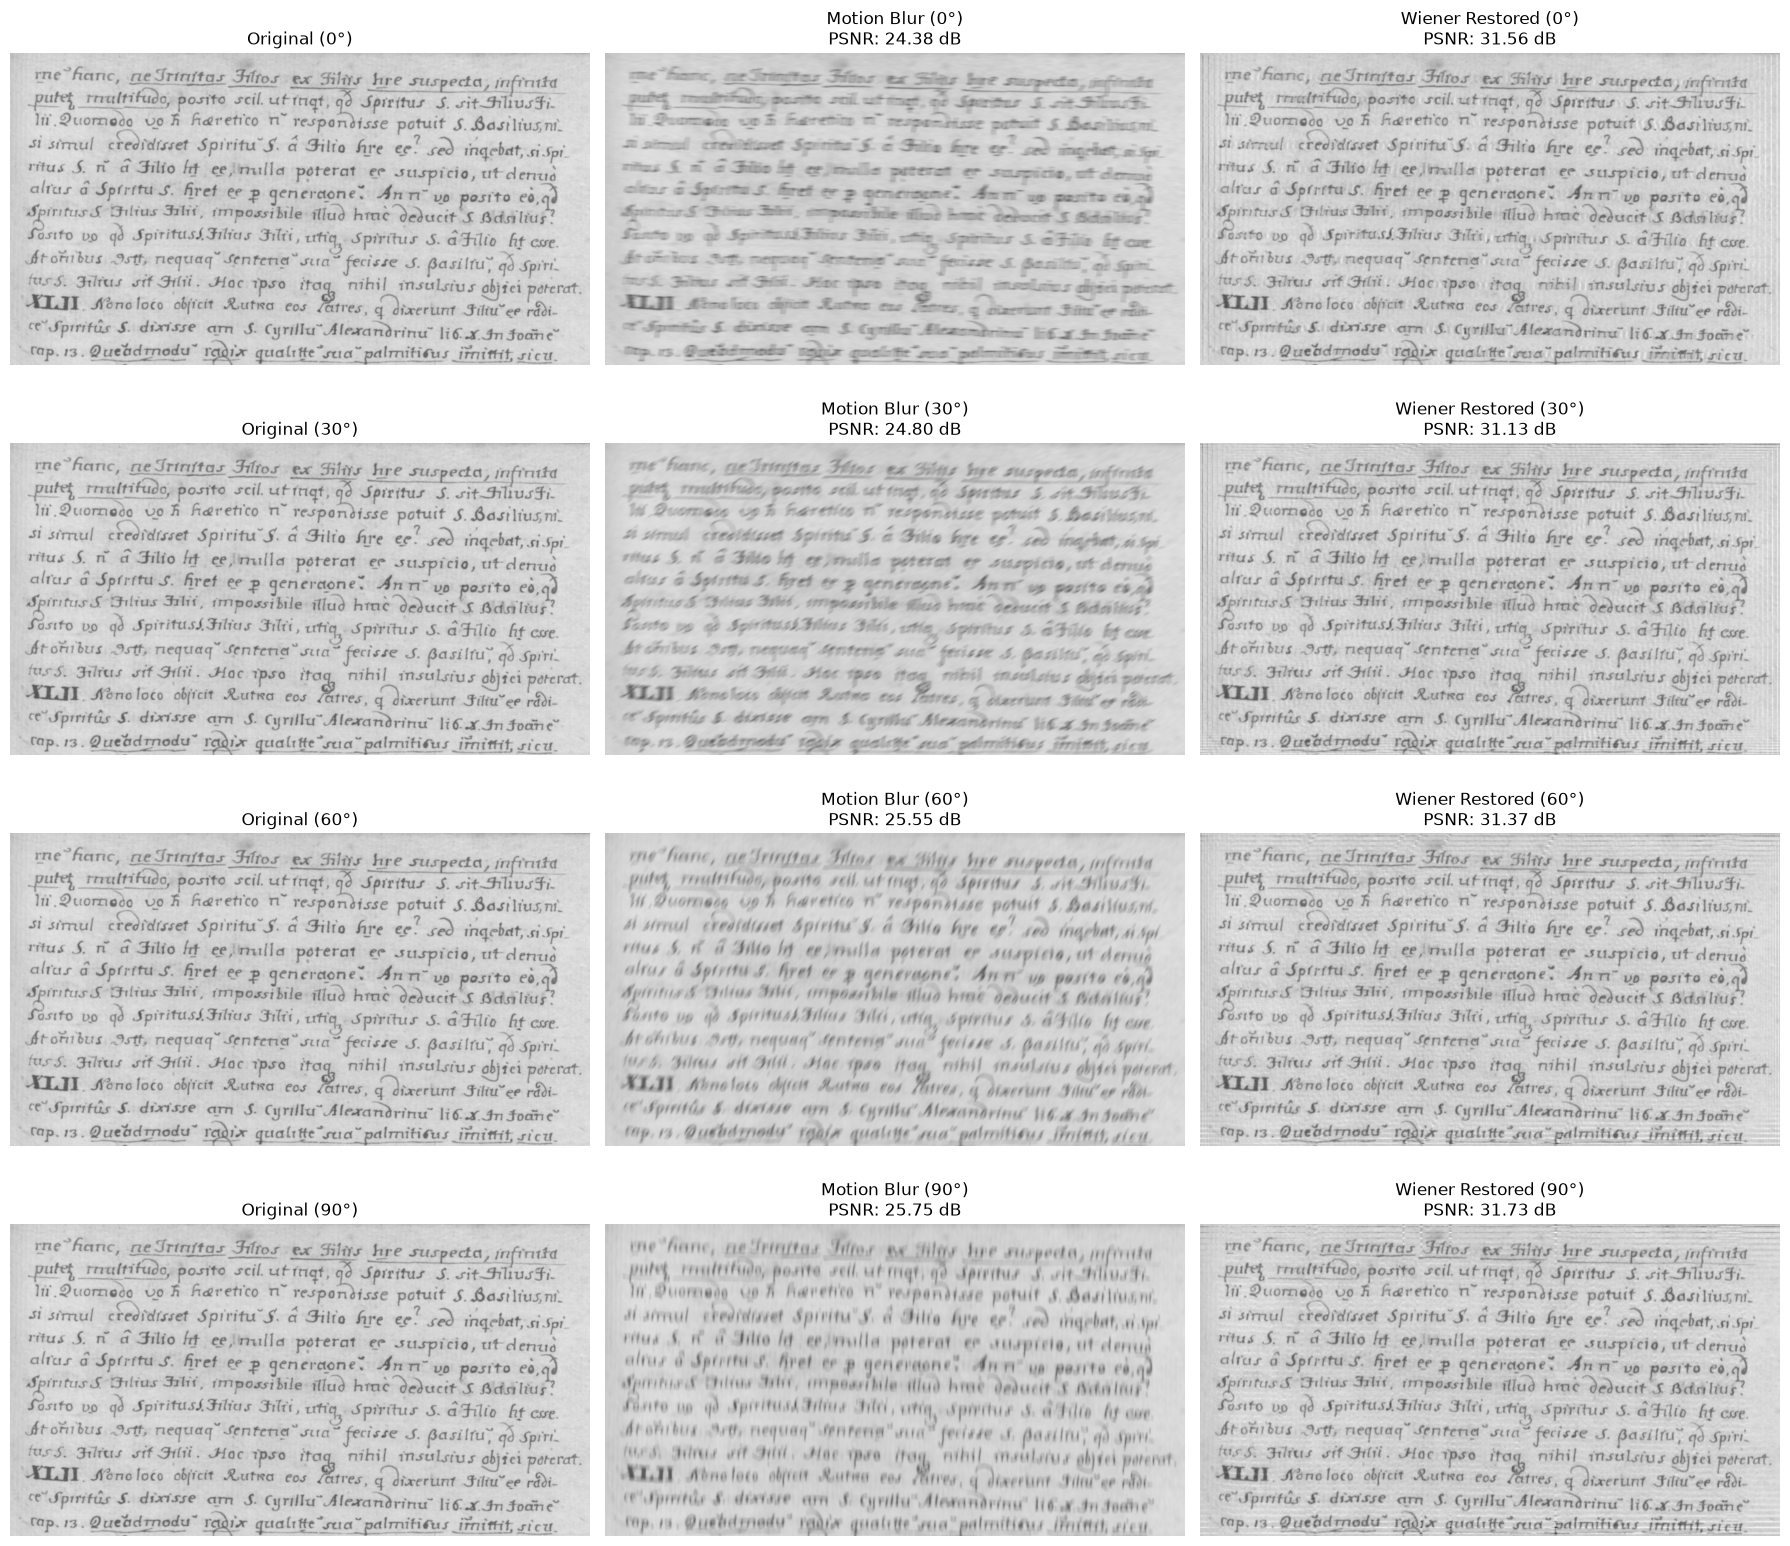

In [116]:
# Motion blur angles to test
angles = [0, 30, 60, 90]

# Create a grid with 4 rows and 3 columns
fig, axes = plt.subplots(4, 3, figsize=(18, 16))

# Loop through each angle
for i, angle in enumerate(angles):

    # Create the motion blur kernel for the current angle
    kernel = create_motion_kernel(15, angle)

    # Apply motion blur to the original manuscript
    blurred = cv2.filter2D(original, -1, kernel)

    # Restore the blurred image using Wiener deconvolution
    restored = wiener_deblur(
        blurred,
        kernel,
        K=0.001887
    )

    # Calculate PSNR for the blurred image
    blurred_score = psnr(original, blurred, data_range=255)

    # Calculate PSNR for the restored image
    restored_score = psnr(original, restored, data_range=255)

    # Store the three images and their titles
    images = [original, blurred, restored]

    titles = [
        f"Original ({angle}°)",
        f"Motion Blur ({angle}°)\nPSNR: {blurred_score:.2f} dB",
        f"Wiener Restored ({angle}°)\nPSNR: {restored_score:.2f} dB"
    ]

    # Display each image in the corresponding row
    for j in range(3):

        axes[i, j].imshow(
            images[j],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[i, j].set_title(titles[j])
        axes[i, j].axis("off")

# Adjust spacing so titles don't overlap
plt.tight_layout()

# Display the comparison
plt.show()

## Automatic Defocus Kernel Estimation — Frequency Analysis

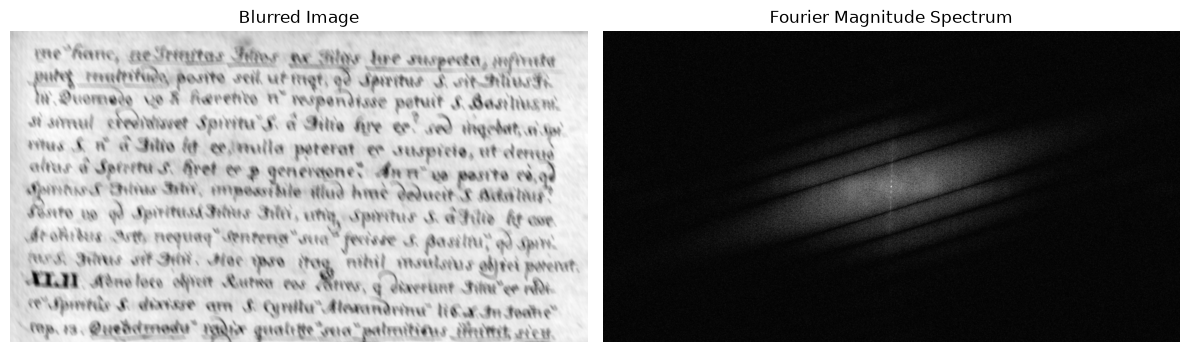

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Generate a known motion blur for testing
test_length = 15
test_angle = 120 

kernel = create_motion_kernel(test_length, test_angle)
blurred = cv2.filter2D(original, -1, kernel)

# Convert the blurred image to floating point
img = blurred.astype(np.float32) / 255.0

# Apply a window to reduce boundary artifacts
window_y = np.hanning(img.shape[0])
window_x = np.hanning(img.shape[1])
window = np.outer(window_y, window_x)

# Compute the Fourier transform
fft = np.fft.fftshift(np.fft.fft2(img * window))

# Calculate the log magnitude spectrum
spectrum = np.log1p(np.abs(fft))

# Display image and frequency spectrum
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(blurred, cmap="gray")
axes[0].set_title("Blurred Image")

axes[1].imshow(spectrum, cmap="gray")
axes[1].set_title("Fourier Magnitude Spectrum")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [118]:
def estimate_motion_angle(fft):
    magnitude = np.abs(fft)
    height, width = magnitude.shape
    cy, cx = height // 2, width // 2

    angles = np.arange(0, 180, 1)
    scores = []

    for angle in angles:
        theta = np.deg2rad(angle)

        # Sample along a line in the Fourier spectrum
        distances = np.arange(10, min(height, width) // 4)

        x = cx + distances * np.cos(theta)
        y = cy + distances * np.sin(theta)

        values = map_coordinates(
            magnitude, [y, x], order=1, mode="nearest"
        )

        # Average frequency energy in this direction
        scores.append(np.mean(np.log1p(values)))

    # Choose the direction with lowest frequency energy
    best_angle = angles[np.argmin(scores)]

    return best_angle


estimated_angle = estimate_motion_angle(fft)
print(f"Estimated motion angle: {estimated_angle}°")

Estimated motion angle: 74°


In [119]:
from skimage.transform import radon
from scipy.ndimage import gaussian_filter

def estimate_motion_angle_radon(fft):
    # Get the Fourier magnitude spectrum
    spectrum = np.log1p(np.abs(fft))

    # Crop the centre to focus on useful frequencies
    h, w = spectrum.shape
    size = min(h, w) // 2

    cy, cx = h // 2, w // 2
    crop = spectrum[
        cy-size//2:cy+size//2,
        cx-size//2:cx+size//2
    ]

    # Smooth the spectrum to reduce small fluctuations
    crop = gaussian_filter(crop, sigma=2)

    # Remove the brightest central frequencies
    crop = crop - np.median(crop)

    # Test angles from 0 to 179 degrees
    angles = np.arange(180)

    # Radon transform detects linear structures
    sinogram = radon(crop, theta=angles, circle=False)

    # Measure variation in the projections
    scores = np.var(sinogram, axis=0)

    # Find strongest orientation
    best_angle = angles[np.argmax(scores)]

    return best_angle


estimated_angle = estimate_motion_angle_radon(fft)
print(f"Estimated motion angle: {estimated_angle}°")


Estimated motion angle: 106°


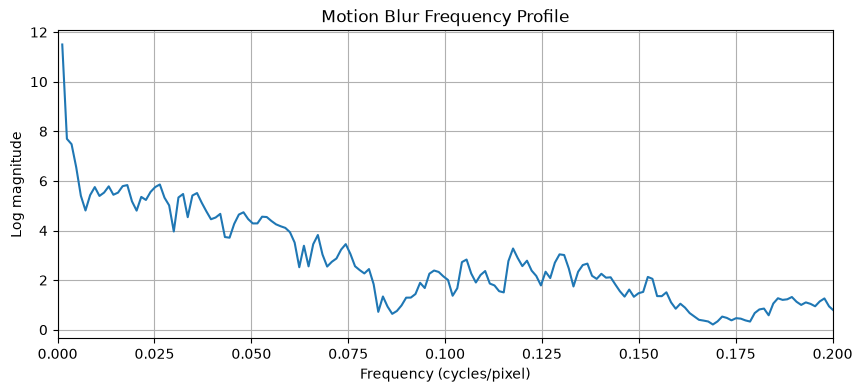

In [120]:
# Plot frequency magnitude along the estimated motion direction
magnitude = np.log1p(np.abs(fft))

h, w = magnitude.shape
cy, cx = h // 2, w // 2

theta = np.deg2rad(estimated_angle)

distances = np.arange(1, min(h, w) // 4)

x = cx + distances * np.cos(theta)
y = cy + distances * np.sin(theta)

profile = map_coordinates(
    magnitude, [y, x], order=1, mode="nearest"
)

frequencies = np.sqrt(
    ((distances * np.cos(theta)) / w)**2 +
    ((distances * np.sin(theta)) / h)**2
)

plt.figure(figsize=(10, 4))
plt.plot(frequencies, profile)

plt.xlabel("Frequency (cycles/pixel)")
plt.ylabel("Log magnitude")
plt.title("Motion Blur Frequency Profile")
plt.xlim(0, 0.2)
plt.grid(True)
plt.show()

In [121]:
# Test possible motion lengths
lengths = np.arange(3, 41)

scores = []

for length in lengths:
    # Expected locations of frequency minima
    expected = np.arange(1, 5) / length
    expected = expected[expected < frequencies[-1]]

    if len(expected) < 2:
        scores.append(np.inf)
        continue

    # Measure spectrum magnitude at expected minima
    values = np.interp(expected, frequencies, profile)

    scores.append(np.mean(values))

estimated_length = lengths[np.argmin(scores)]

print(f"Estimated motion length: {estimated_length} px")

Estimated motion length: 12 px


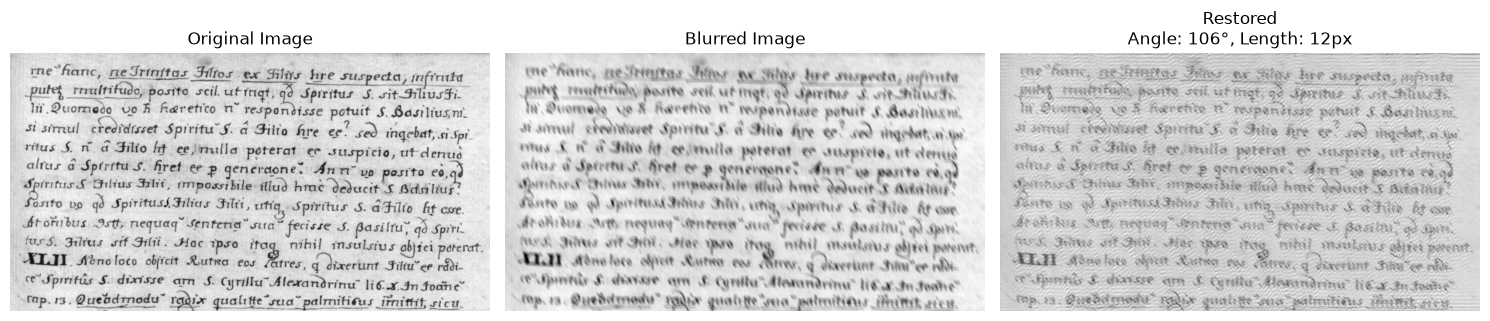

Blurred PSNR: 24.93 dB
Restored PSNR: 23.57 dB


In [122]:
# Restore motion blur using estimated parameters

if estimated_length is not None:
    # Create a kernel using our estimated values
    estimated_kernel = create_motion_kernel(
        int(round(estimated_length)),
        float(estimated_angle)
    )

    # Reverse the blur using Wiener deconvolution
    restored = wiener_deblur(
        blurred,
        estimated_kernel,
        K=0.001887
    )

    # Display the results
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(original, cmap="gray")
    axes[0].set_title("Original Image")

    axes[1].imshow(blurred, cmap="gray")
    axes[1].set_title("Blurred Image")

    axes[2].imshow(restored, cmap="gray")
    axes[2].set_title(
        f"Restored\nAngle: {estimated_angle}°, "
        f"Length: {estimated_length:.0f}px"
    )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print(f"Blurred PSNR: {cv2.PSNR(original, blurred):.2f} dB")
    print(f"Restored PSNR: {cv2.PSNR(original, restored):.2f} dB")

else:
    print("Could not estimate motion length.")